<a href="https://colab.research.google.com/github/izzat-ai/learning-ai/blob/main/projects/customer_churn/bank_churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [33]:
# Google Drive'ni ulash
from google.colab import drive
drive.mount('/content/drive')

import os

# Loyiha joylashgan papka manzillari
BASE = "/content/drive/MyDrive/AI learning/ai_project_2026/sertificate_projects"
PROJECT = BASE + "/churn_project"

# Loyiha hali ochilmagan bo'lsa, files.zip ni ochish (faqat birinchi marta ishlaydi)
if not os.path.exists(PROJECT + "/data/train.csv"):
    !unzip -o -q "{BASE}/files.zip" -d /content/tmp
    !unzip -o -q /content/tmp/churn_project.zip -d "{BASE}"

# Loyiha papkasiga o'tish
os.chdir(PROJECT)
os.makedirs("models", exist_ok=True)

# Natijani tekshirish
print("Ish papkasi:", os.getcwd())
!ls data

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ish papkasi: /content/drive/MyDrive/AI learning/ai_project_2026/sertificate_projects/churn_project
sample_submission.csv  test.csv  train.csv


In [34]:
# kutubxonalarni import qilish
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

# Grafiklar
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Natijalar har safar bir xil chiqishi uchun random_state belgilash
RANDOM_STATE = 42

In [35]:
# train.csv va test.csv fayllarini yuklash
train = pd.read_csv("/content/drive/MyDrive/AI learning/ai_project_2026/bank_prediction/train.csv")
test = pd.read_csv("/content/drive/MyDrive/AI learning/ai_project_2026/bank_prediction/test.csv")

# Jadvallar o'lchamini ko'rish
print("Train o'lchami:", train.shape)
print("Test o'lchami :", test.shape)

Train o'lchami: (15000, 14)
Test o'lchami : (10000, 13)


In [36]:
train.head()

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15702656.0,Nwora,567.0,France,Male,33.0,9.0,0.0,2.0,1.0,0.0,156792.89,0.0
1,1,15647965.0,Yevdokimova,628.0,France,Female,38.0,3.0,0.0,1.0,1.0,1.0,51987.99,1.0
2,2,15798834.0,Ch'iu,635.0,France,Female,29.0,3.0,0.0,2.0,1.0,1.0,113079.19,0.0
3,3,15672056.0,Hsia,681.0,France,Male,28.0,6.0,0.0,2.0,1.0,0.0,14081.64,0.0
4,4,15759537.0,Okwudilichukwu,587.0,France,Female,27.0,5.0,0.0,2.0,1.0,0.0,158958.90,0.0


In [37]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               15000 non-null  int64  
 1   CustomerId       15000 non-null  float64
 2   Surname          15000 non-null  object 
 3   CreditScore      15000 non-null  float64
 4   Geography        15000 non-null  object 
 5   Gender           15000 non-null  object 
 6   Age              15000 non-null  float64
 7   Tenure           15000 non-null  float64
 8   Balance          15000 non-null  float64
 9   NumOfProducts    15000 non-null  float64
 10  HasCrCard        15000 non-null  float64
 11  IsActiveMember   15000 non-null  float64
 12  EstimatedSalary  15000 non-null  float64
 13  Exited           15000 non-null  float64
dtypes: float64(10), int64(1), object(3)
memory usage: 1.6+ MB


In [38]:
# ba'zi ustunlarni int turiga o'zgartirish
int_cols = [
    'Age',
    'Tenure',
    'NumOfProducts',
    'HasCrCard',
    'IsActiveMember',
    'Exited',
]
for col in int_cols:
  train[col] = train[col].astype(int)

In [39]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               15000 non-null  int64  
 1   CustomerId       15000 non-null  float64
 2   Surname          15000 non-null  object 
 3   CreditScore      15000 non-null  float64
 4   Geography        15000 non-null  object 
 5   Gender           15000 non-null  object 
 6   Age              15000 non-null  int64  
 7   Tenure           15000 non-null  int64  
 8   Balance          15000 non-null  float64
 9   NumOfProducts    15000 non-null  int64  
 10  HasCrCard        15000 non-null  int64  
 11  IsActiveMember   15000 non-null  int64  
 12  EstimatedSalary  15000 non-null  float64
 13  Exited           15000 non-null  int64  
dtypes: float64(4), int64(7), object(3)
memory usage: 1.6+ MB


In [40]:
# sonli ustunlarni ma'lumotlarini ko'rish
train.describe().round(2)

,id,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,15000.00,1.500000e+04,15000.00,15000.00,15000.00,15000.00,15000.00,15000.00,15000.0,15000.00,15000.0
mean,7499.50,1.579454e+07,657.86,37.71,5.02,42338.11,1.59,0.78,0.5,116944.06,0.2
std,4330.27,1.268495e+07,72.68,8.14,2.79,59703.05,0.53,0.41,0.5,46047.49,0.4
min,0.00,1.567151e+05,431.00,18.00,0.00,0.00,1.00,0.00,0.0,11.58,0.0
25%,3749.75,1.563435e+07,602.00,32.00,3.00,0.00,1.00,1.00,0.0,82644.33,0.0
50%,7499.50,1.568947e+07,661.00,37.00,5.00,0.00,2.00,1.00,0.0,122449.42,0.0
75%,11249.25,1.575682e+07,707.00,42.00,7.00,109636.34,2.00,1.00,1.0,155703.02,0.0
max,14999.00,1.569172e+09,850.00,72.00,10.00,187911.55,5.00,1.00,1.0,885120.79,1.0


- mijozlarning taxminan 20% i bankni tark etgan, 80% i qolgan . Bundan ma'lumotlarimiz balansda emasligi tushuniladi . Modelni o'rgatishda buni hisobga olish

In [41]:
# har bir sinfdagi mijozlar sonini va foizini hisoblash
churn_counts = train["Exited"].value_counts()
churn_percent = train["Exited"].value_counts(normalize=True) * 100
print(churn_counts)
print(churn_percent.round(2))

Exited
0    12023
1     2977
Name: count, dtype: int64
Exited
0    80.15
1    19.85
Name: proportion, dtype: float64


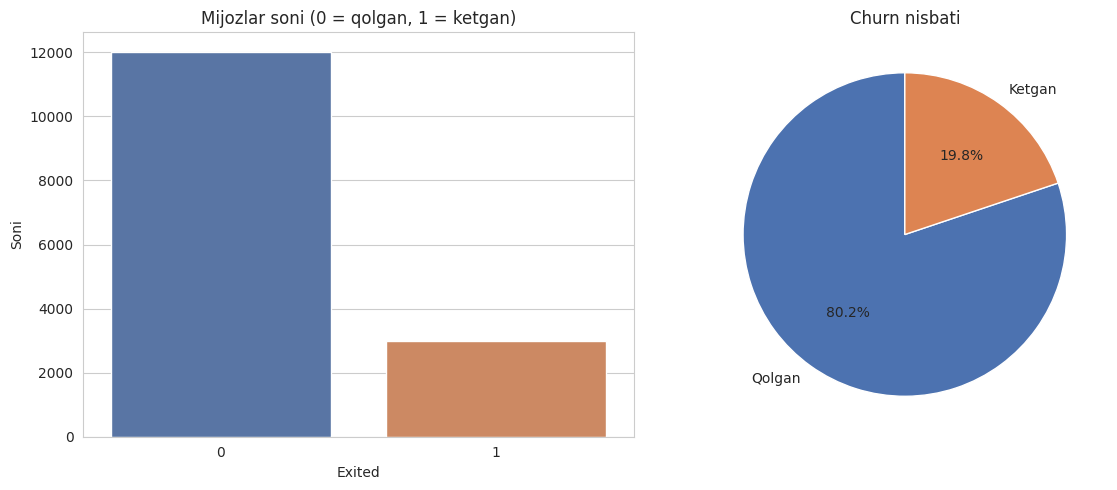

In [42]:
# ketgan va qolgan mijozlar grafigini chizish
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(x="Exited", hue="Exited", data=train, ax=axes[0], palette=["#4C72B0", "#DD8452"], legend=False)
axes[0].set_title("Mijozlar soni (0 = qolgan, 1 = ketgan)")
axes[0].set_xlabel("Exited")
axes[0].set_ylabel("Soni")

axes[1].pie(churn_counts, labels=["Qolgan", "Ketgan"], autopct="%1.1f%%",
            colors=["#4C72B0", "#DD8452"], startangle=90)
axes[1].set_title("Churn nisbati")

plt.tight_layout()
plt.show()

- **Xulosa:** Mijozlarning 80% qolgan, 20% ketgan. Bu balansda bo'lmagan ma'lumot. Shuning uchun faqat Accuracy ga ishonib bo'lmaydi . Hamma mijozni qoladi deb bashorat qiluvchi model ham 80% accuracy beradi. Biz Recall, F1-score va ROC-AUC ga ham qarashimiz kerak .

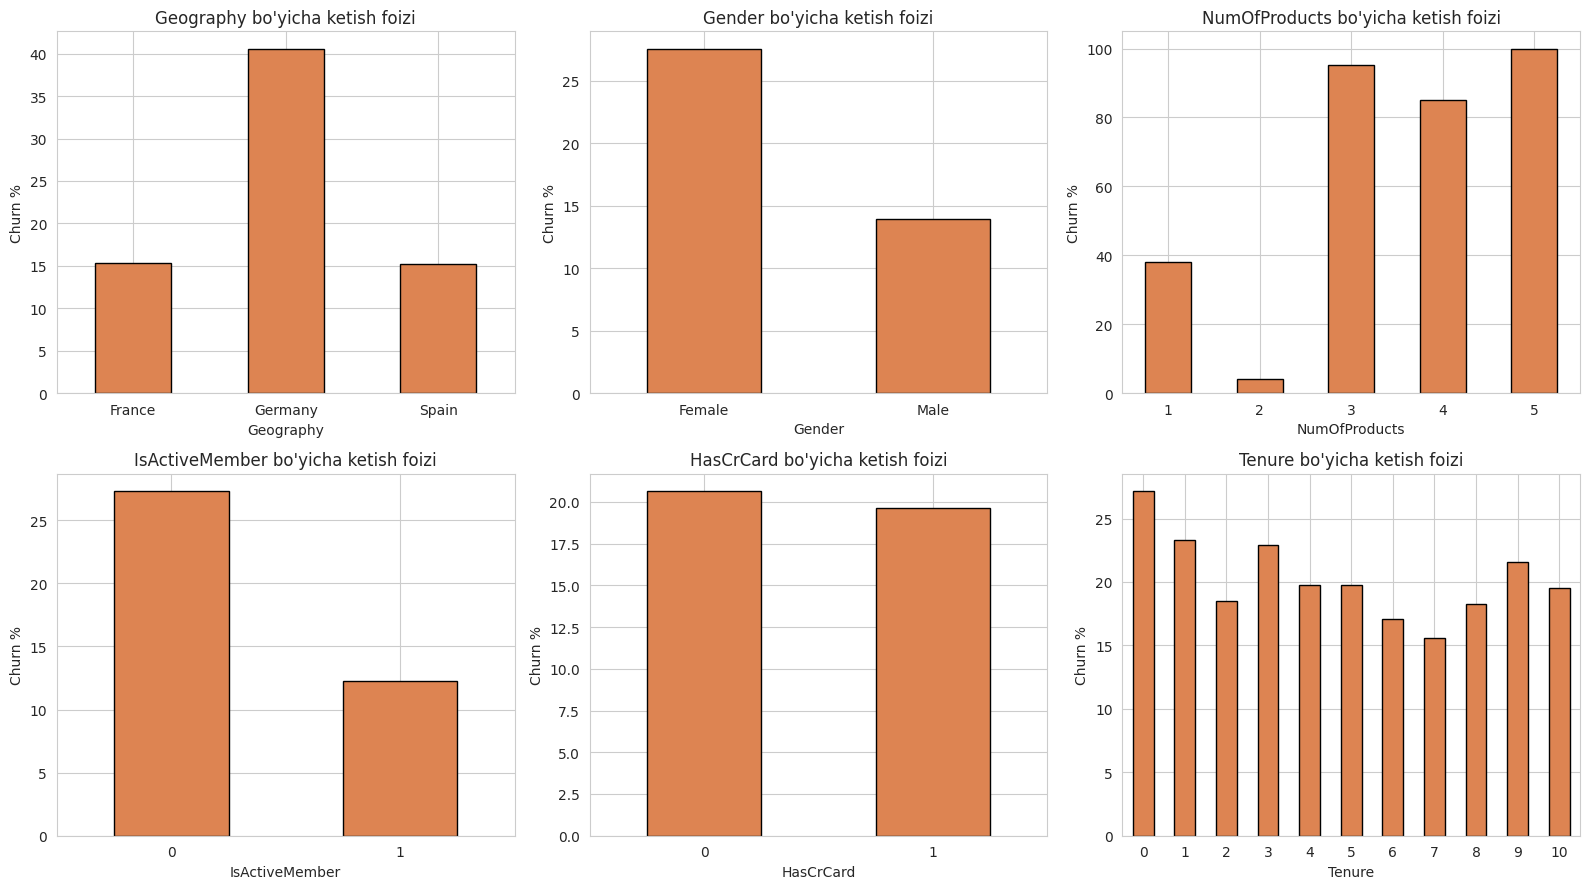

In [43]:
# Kategorik ustunlar ro'yxatini yaratish
cat_features = ["Geography", "Gender", "NumOfProducts", "IsActiveMember", "HasCrCard", "Tenure"]

# Har bir kategoriya uchun ketish foizini grafikda ko'rsatish
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    churn_rate = train.groupby(col)["Exited"].mean() * 100
    churn_rate.plot(kind="bar", ax=axes[i], color="#DD8452", edgecolor="black")
    axes[i].set_title(f"{col} bo'yicha ketish foizi")
    axes[i].set_ylabel("Churn %")
    axes[i].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [44]:
# yuqoridagi ma'lumotlarni jadval ko'rinishida chiqarish
for col in ["Geography", "Gender", "IsActiveMember", "NumOfProducts"]:
    print(f"--- {col} ---")
    print((train.groupby(col)["Exited"].mean() * 100).round(1), "\n")

--- Geography ---
Geography
France     15.4
Germany    40.6
Spain      15.2
Name: Exited, dtype: float64 

--- Gender ---
Gender
Female    27.6
Male      13.9
Name: Exited, dtype: float64 

--- IsActiveMember ---
IsActiveMember
0    27.3
1    12.3
Name: Exited, dtype: float64 

--- NumOfProducts ---
NumOfProducts
1     38.0
2      4.2
3     95.4
4     85.0
5    100.0
Name: Exited, dtype: float64 



> **Xulosa:**

- Geography: Germaniyadagi mijozlarni 41% ketgan, Fransiya va Ispaniyada esa 15%. Germaniya — xavfli hudud.
- Gender: Ayollar (28%) erkaklarga (14%) qaraganda ko'proq ketadi.
- IsActiveMember: Faol bo'lmagan mijozlar (27%) faol mijozlarga (12%) nisbatan 2 barobar ko'p ketadi.
- NumOfProducts: Eng qiziq belgi. 2 ta mahsulotli mijozlar deyarli ketmaydi (4%), 1 ta mahsulotlilar 38%, 3-4 ta mahsulotlilar esa 85-95% ketgan. Bog'liqlik chiziqli emas .  (U-shakl) — bu daraxtga asoslangan modellar (Random Forest, XGBoost) afzalligini ko'rsatadi.
- HasCrCard va Tenure churn'ga deyarli ta'sir qilmaydi.

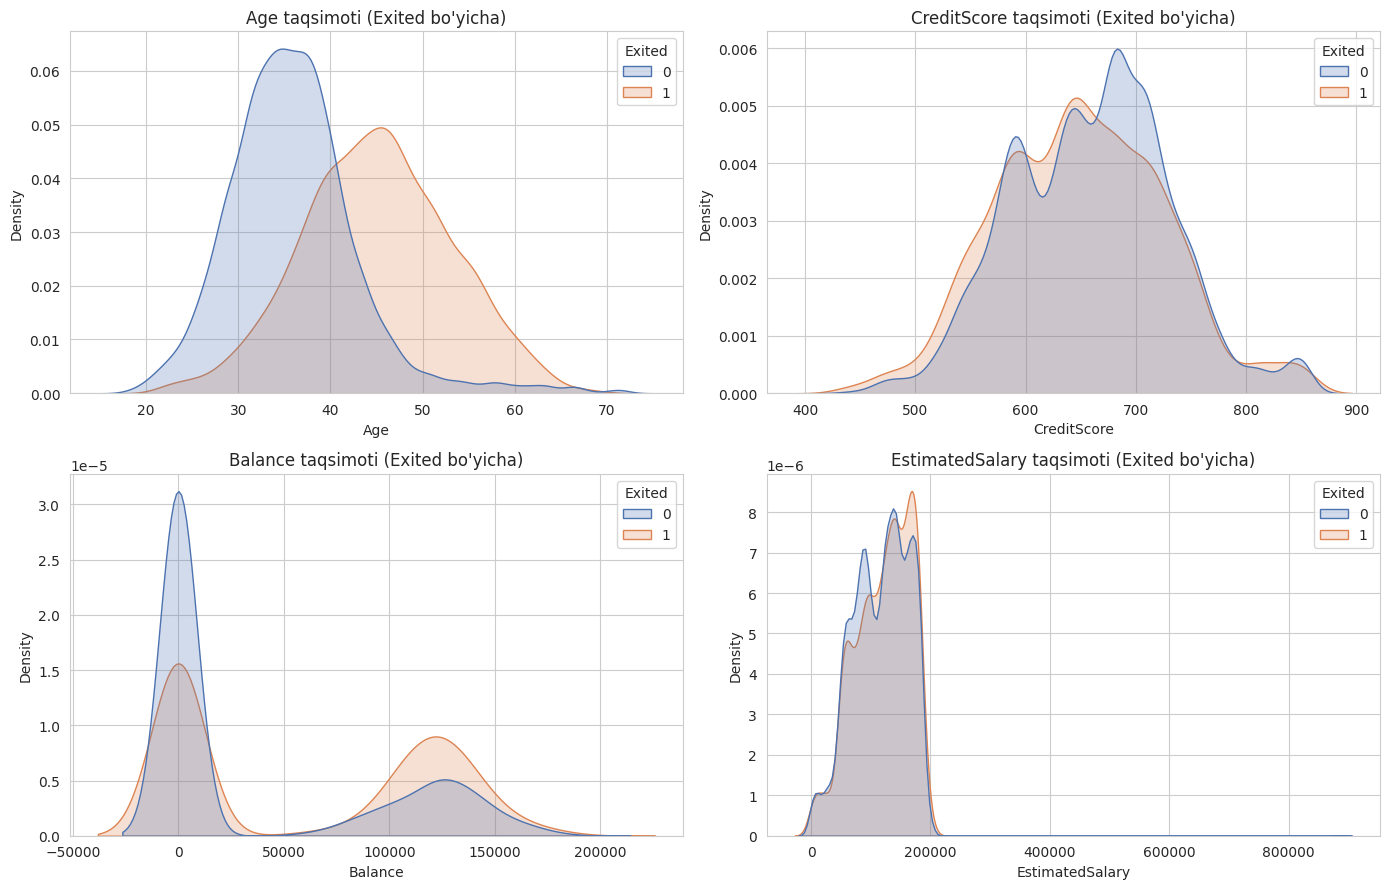

In [45]:
# Sonli ustunlar ro'yxatini yaratish
num_features = ["Age", "CreditScore", "Balance", "EstimatedSalary"]

# Ketgan va qolgan mijozlar taqsimotini solishtirish
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i, col in enumerate(num_features):
    sns.kdeplot(data=train, x=col, hue="Exited", fill=True,
                common_norm=False, ax=axes[i], palette=["#4C72B0", "#DD8452"])
    axes[i].set_title(f"{col} taqsimoti (Exited bo'yicha)")

plt.tight_layout()
plt.show()

In [46]:
# Ketgan va qolgan mijozlar o'rtasidagi medianalarni solishtirish
train.groupby("Exited")[num_features].median().round(1)

,Age,CreditScore,Balance,EstimatedSalary
Exited,,,,
0,35.0,663.0,0.0,121551.9
1,45.0,648.0,61671.2,126561.1


**Xulosa:**

- Age — eng kuchli sonli ustun. Ketgan mijozlarning o'rtacha yoshi 45, qolganlarniki 35. 40-60 yoshdagi mijozlar ko'proq ketadi.
- Balance — hisobida pul bor mijozlar ko'proq ketadi. Ko'p mijozlarning balansi 0 ga teng.
- CreditScore va EstimatedSalary bo'yicha ketgan va qolganlar taqsimoti deyarli bir xil — ular kuchsiz belgilar.

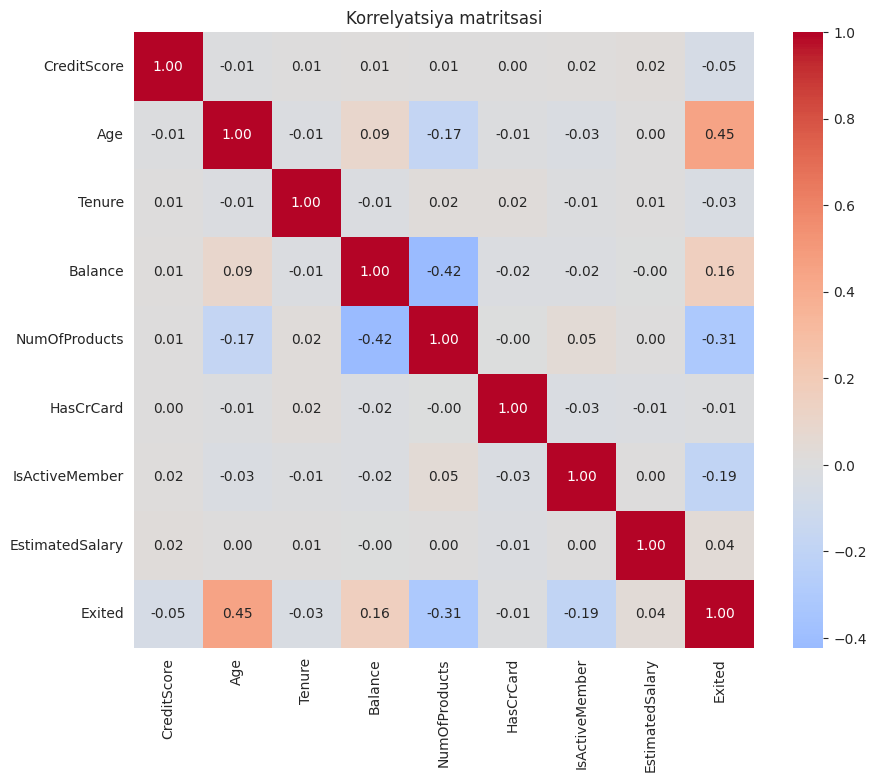

In [47]:
# Faqat sonli ustunlarni tanlash (ID ustunlarisiz)
numeric_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
                "HasCrCard", "IsActiveMember", "EstimatedSalary", "Exited"]

# Korrelyatsiya matritsasini hisoblash va chizish
corr = train[numeric_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korrelyatsiya matritsasi")
plt.show()

- `Exited` bilan eng kuchli bog'liqlik: Age ustunidir va NumOfProducts , IsActiveMember va Balance . Belgilar o'rtasida kuchli o'zaro korrelyatsiya yo'q.
- korrelyatsiya faqat chiziqli bog'liqlikni o'lchaydi, shuning uchun NumOfProducts ning ta'siri bu yerda to'liq ko'rinmaydi

**Ma'lumotlarni Tayyorlash**

In [48]:
# Etishmayotgan qiymatlarni tekshirish
print("Train dagi bo'sh qiymatlar:", train.isnull().sum().sum())
print("Test dagi bo'sh qiymatlar :", test.isnull().sum().sum())

# Dublikatlarni tekshirish (id ustunisiz)
print("Train dagi dublikatlar   :", train.drop(columns="id").duplicated().sum())

Train dagi bo'sh qiymatlar: 0
Test dagi bo'sh qiymatlar : 0
Train dagi dublikatlar   : 0


- Ma'lumotlarda bo'sh qiymatlar ham, dublikatlar ham yo'q. Shuning uchun to'ldirish yoki o'chirish kerak emas

In [49]:
# Test id larini submission uchun alohida saqlab qo'yish
test_ids = test["id"]

# Ketishga ta'sir qilmaydigan identifikator ustunlarini olib tashlash
drop_cols = ["id", "CustomerId", "Surname"]
train_clean = train.drop(columns=drop_cols)
test_clean = test.drop(columns=drop_cols)

train_clean.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,567.0,France,Male,33,9,0.0,2,1,0,156792.89,0
1,628.0,France,Female,38,3,0.0,1,1,1,51987.99,1
2,635.0,France,Female,29,3,0.0,2,1,1,113079.19,0
3,681.0,France,Male,28,6,0.0,2,1,0,14081.64,0
4,587.0,France,Female,27,5,0.0,2,1,0,158958.90,0


In [50]:
# Geography va Gender ustunlarini One-Hot Encoding qilish
cat_cols = ["Geography", "Gender"]
train_encoded = pd.get_dummies(train_clean, columns=cat_cols, drop_first=True, dtype=int)
test_encoded = pd.get_dummies(test_clean, columns=cat_cols, drop_first=True, dtype=int)

train_encoded.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,567.0,33,9,0.0,2,1,0,156792.89,0,0,0,1
1,628.0,38,3,0.0,1,1,1,51987.99,1,0,0,0
2,635.0,29,3,0.0,2,1,1,113079.19,0,0,0,0
3,681.0,28,6,0.0,2,1,0,14081.64,0,0,0,1
4,587.0,27,5,0.0,2,1,0,158958.90,0,0,0,0


- `Geography` → Geography_Germany , Geography_Spain (France — bazaviy kategoriya), `Gender` → Gender_Male (Female — bazaviy). `drop_first=True` ortiqcha ustunni olib tashlaydi

**X va y ga ajratish**

In [51]:
# Belgilar (X) va target ustunini (y) ajratish
X = train_encoded.drop(columns="Exited")
y = train_encoded["Exited"].astype(int)

# test.csv ustunlarini train bilan aynan bir xil tartibga keltirish
X_test = test_encoded.reindex(columns=X.columns, fill_value=0)

print("X shakli     :", X.shape)
print("X_test shakli:", X_test.shape)
print("Ustunlar     :", list(X.columns))

X shakli     : (15000, 11)
X_test shakli: (10000, 11)
Ustunlar     : ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']


**Train va Validation to'plamlariga bo'lish**

In [52]:
# Ma'lumotni 80% train va 20% validation ga bo'lish
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y          # Ikkala to'plamda churn nisbatini bir xil saqlash
)

print("Train:", X_train.shape, "| Churn %:", round(y_train.mean() * 100, 2))
print("Val  :", X_val.shape, "| Churn %:", round(y_val.mean() * 100, 2))

Train: (12000, 11) | Churn %: 19.85
Val  : (3000, 11) | Churn %: 19.83


- `stratify=y` tufayli train va validation to'plamlarida churn nisbati bir xil (19.8%). Bu validation natijalarining ishonchli bo'lishini ta'minlaydi

**Standartlashtirish**

In [53]:
# Scaler yaratish
scaler = StandardScaler()

# Scalerni faqat train ma'lumotida o'qitish (fit) va o'zgartirish
X_train_scaled = scaler.fit_transform(X_train)

# Validation va testga aynan scalerni qo'llash
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Natijani tekshirish: trainda o'rtacha 0, standart og'ish 1 bo'lishi kerak
print("O'rtacha qiymatlar :", X_train_scaled.mean(axis=0).round(2))
print("Standart og'ishlar :", X_train_scaled.std(axis=0).round(2))

O'rtacha qiymatlar : [ 0.  0.  0. -0.  0. -0. -0.  0.  0. -0. -0.]
Standart og'ishlar : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Scaler faqat `X_train` da `fit` qilindi, validation va test'ga faqat `transform` qo'llandi. Bu **data leakage** (ma'lumot sizib chiqishi)ning oldini oladi — model validation/test haqida oldindan hech narsa bilmaydi. Standartlashtirish ayniqsa Logistic Regression uchun muhim, chunki u belgilar masshtabiga sezgir

**Modellarni yaratish va o'qitish**

In [54]:
# Uchta modelni lug'atga joylash
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=10,
                                            random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                             random_state=RANDOM_STATE, eval_metric="logloss"),
}

In [55]:
# Har bir modelni o'qitish va natijalarini saqlash
results = []
predictions = {}

for name, model in models.items():
    # Modelni o'qitish
    model.fit(X_train_scaled, y_train)

    # Validation uchun sinf va ehtimollarni bashorat qilish
    y_pred = model.predict(X_val_scaled)
    y_proba = model.predict_proba(X_val_scaled)[:, 1]
    predictions[name] = y_pred

    # Metrikalarni hisoblash
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1-score": f1_score(y_val, y_pred),
        "ROC-AUC": roc_auc_score(y_val, y_proba),
    })
    print(f"{name} o'qitildi.")

Logistic Regression o'qitildi.
Random Forest o'qitildi.
XGBoost o'qitildi.


**Modellarni solishtirish**

In [56]:
# Natijalarni jadval ko'rinishiga keltirish
results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df.sort_values("ROC-AUC", ascending=False)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
XGBoost,0.8953,0.7666,0.6790,0.7201,0.9330
Random Forest,0.8970,0.7955,0.6471,0.7136,0.9324
Logistic Regression,0.8737,0.7512,0.5429,0.6302,0.8838


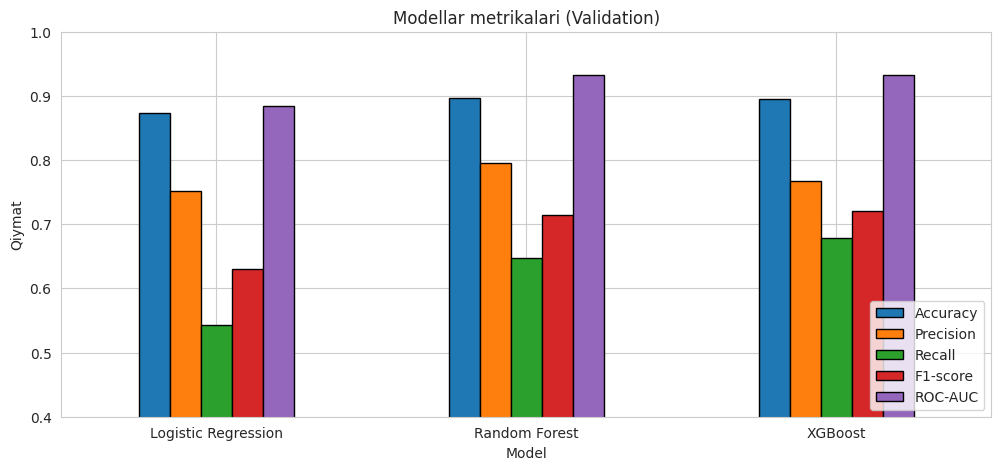

In [57]:
# Metrikalarni grafikda solishtirish
results_df.plot(kind="bar", figsize=(12, 5), edgecolor="black")
plt.title("Modellar metrikalari (Validation)")
plt.ylabel("Qiymat")
plt.ylim(0.4, 1.0)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

- Random Forest va XGBoostlar Logistic Regressiondan ancha yaxshi. Sababi — EDA'da ko'rganimizdek, `NumOfProducts` va `Age` churn bilan chiziqli bo'lmagan bog'liqlikka ega, Logistic Regression esa faqat chiziqli chegaralarni o'rgana oladi. XGBoost eng yuqori ROC-AUC va F1-score'ni ko'rsatdi.

**Confusion Matrix**

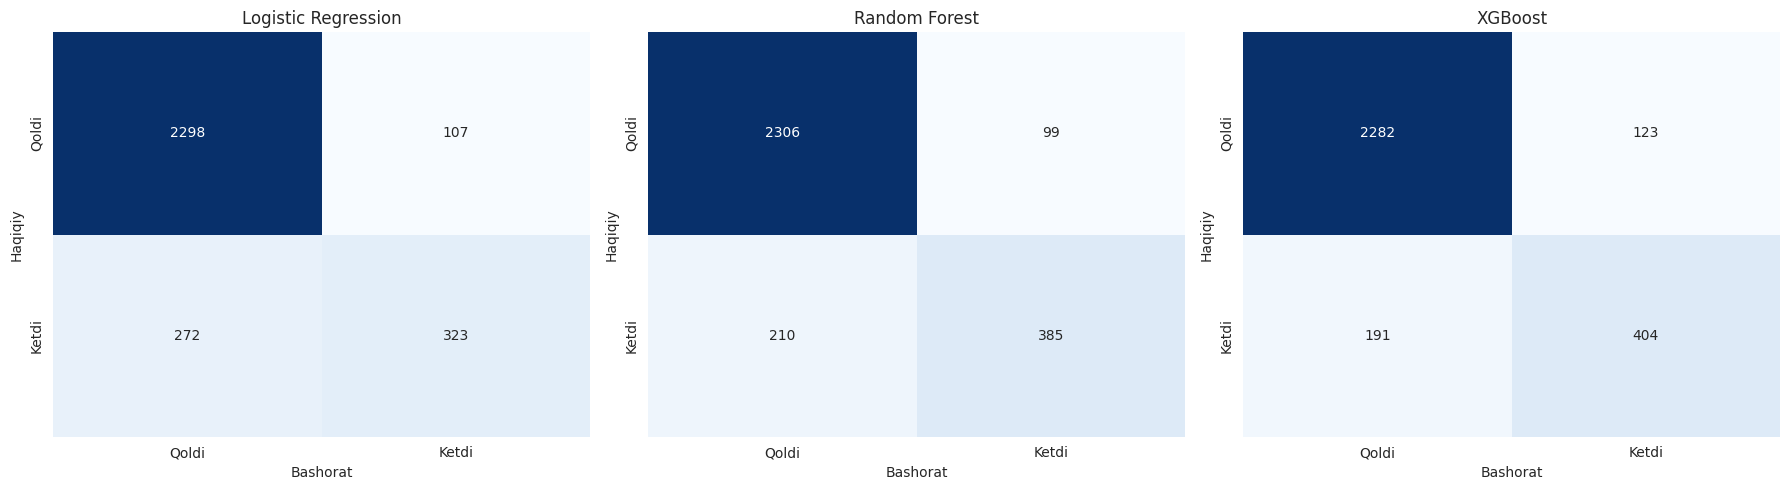

In [58]:
# Har bir model uchun Confusion Matrix chizish
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_val, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[i], cbar=False,
                xticklabels=["Qoldi", "Ketdi"], yticklabels=["Qoldi", "Ketdi"])
    axes[i].set_title(name)
    axes[i].set_xlabel("Bashorat")
    axes[i].set_ylabel("Haqiqiy")

plt.tight_layout()
plt.show()

Confusion Matrixda eng muhim katak — pastki chap burchak ya'ni False Negativedir . Aslida ketgan, lekin model qoladi deb aytgan mijozlar. Bank uchun bu eng katta xato, chunki biz bu mijozni yo'qotamiz. XGBoost eng kam False Negativega ega model bo'ldi

In [59]:
# ROC-AUC bo'yicha eng yaxshi modelni tanlash
best_model_name = results_df["ROC-AUC"].idxmax()
best_model = models[best_model_name]
print("Eng yaxshi model:", best_model_name)

# Eng yaxshi model uchun batafsil hisobotni chiqarish
print(classification_report(y_val, predictions[best_model_name],
                            target_names=["Qoldi", "Ketdi"]))

Eng yaxshi model: XGBoost
              precision    recall  f1-score   support

       Qoldi       0.92      0.95      0.94      2405
       Ketdi       0.77      0.68      0.72       595

    accuracy                           0.90      3000
   macro avg       0.84      0.81      0.83      3000
weighted avg       0.89      0.90      0.89      3000



Model tanlash uchun **ROC-AUC** ishlatildi, chunki: birinchidan ma'lumot nomutanosib, ikkinchidan `sample_submission.csv` formatida `Exited` ehtimol sifatida (0.5) berilgan — demak, bizdan aniq klassifikatsiya emas, ehtimol kutilyapti. ROC-AUC modelning ehtimollar bo'yicha mijozlarni qanchalik to'g'ri saralashini o'lchaydi

**Ustunlar muhimligi**

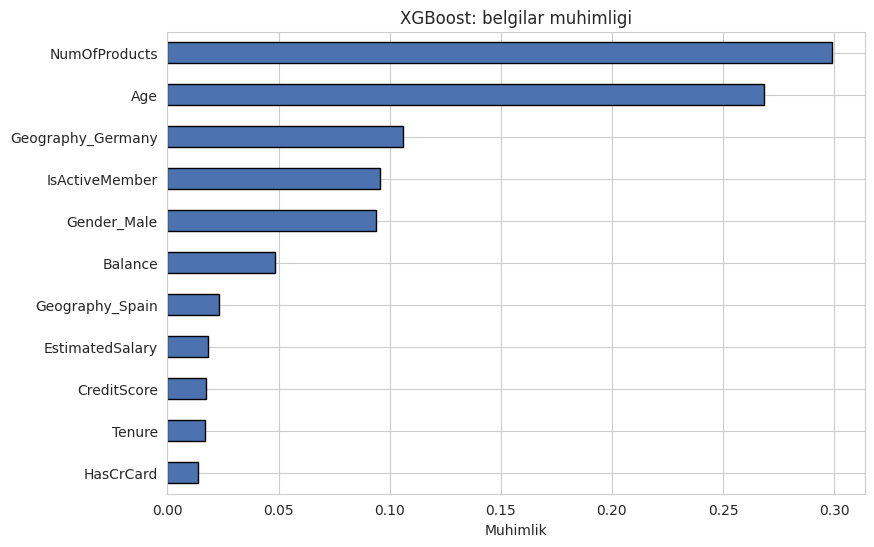

In [60]:
# Eng yaxshi modelning belgilar muhimligini olish
importance = pd.Series(best_model.feature_importances_, index=X.columns)
importance = importance.sort_values()

# Belgilar muhimligi grafigini chizish
importance.plot(kind="barh", figsize=(9, 6), color="#4C72B0", edgecolor="black")
plt.title(f"{best_model_name}: belgilar muhimligi")
plt.xlabel("Muhimlik")
plt.show()

Model uchun eng muhim belgilar — NumOfProducts, Age, IsActiveMember va Geography_Germany. Bu EDA natijalarimizga to'liq mos keladi, demak model mantiqiy qonuniyatlarni o'rgangan.

**Biznes tavsiyasi:** 40+ yoshli, faol bo'lmagan, 1 ta mahsulotga ega va Germaniyadagi mijozlarga e'tiborni kuchaytirish kerak

**test qilish (test.csv) bilan**

In [61]:
# test.csv uchun ketish ehtimolini bashorat qilish
test_proba = best_model.predict_proba(X_test_scaled)[:, 1]

# sample_submission.csv formatini yuklash
submission = pd.read_csv("data/sample_submission.csv")

# Prognozlarni submission jadvaliga yozish
submission["Exited"] = test_proba

# id'lar to'g'ri tartibda ekanini tekshirish
assert (submission["id"].values == test_ids.values).all()

# Natijani faylga saqlash
submission.to_csv("submission.csv", index=False)
submission.head()

,id,Exited
0,15000,0.019916
1,15001,0.125144
2,15002,0.022777
3,15003,0.108151
4,15004,0.006681


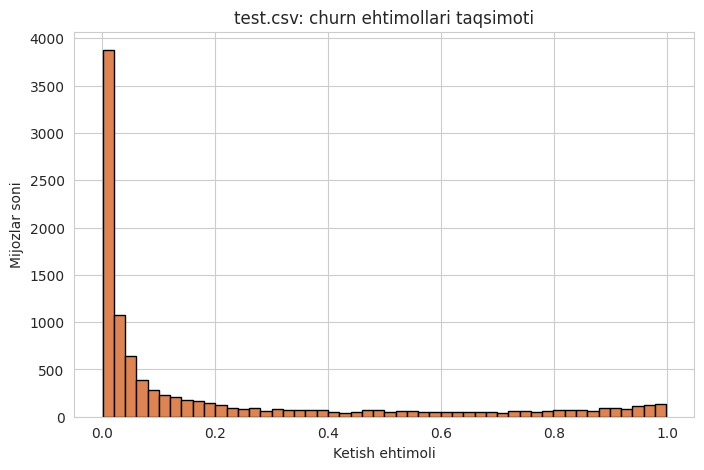

O'rtacha bashorat qilingan churn ehtimoli: 0.201


In [62]:
# Prognoz qilingan ehtimollar taqsimotini ko'rish
plt.hist(test_proba, bins=50, color="#DD8452", edgecolor="black")
plt.title("test.csv: churn ehtimollari taqsimoti")
plt.xlabel("Ketish ehtimoli")
plt.ylabel("Mijozlar soni")
plt.show()

print("O'rtacha bashorat qilingan churn ehtimoli:", round(test_proba.mean(), 3))

test.csvdagi 10 000 mijoz uchun ketish ehtimollari hisoblandi va `submission.csv` ga saqlandi. O'rtacha ehtimol (0.20) traindagi churn nisbatiga yaqin — bu modelning to'g'ri o'qitilganini ko'rsatadi. Ko'pchilik mijozlarning ehtimoli 0 ga yaqin, kichik guruhda esa juda yuqori — aynan shu guruh bank uchun maqsadli auditoriya hisoblanadi

**Modelni Saqlash**

In [63]:
# Eng yaxshi modelni faylga saqlash
joblib.dump(best_model, "models/churn_model.pkl")

# Scalerni faylga saqlash (yangi ma'lumotga aynan shu transformatsiyani qo'llash uchun)
joblib.dump(scaler, "models/scaler.pkl")

# Ustunlar tartibini saqlash (Streamlit ilovasida bir xil tartibni ta'minlash uchun)
joblib.dump(list(X.columns), "models/feature_columns.pkl")

print("Model, scaler va ustunlar saqlandi")

Model, scaler va ustunlar saqlandi


In [64]:
# Saqlangan fayllarni qayta yuklab tekshirish
loaded_model = joblib.load("models/churn_model.pkl")
loaded_scaler = joblib.load("models/scaler.pkl")

# Validationdagi birinchi mijoz uchun natijani solishtirish
sample = loaded_scaler.transform(X_val.iloc[[0]])
print("Saqlangan model ehtimoli:", round(loaded_model.predict_proba(sample)[0, 1], 4))
print("Asl model ehtimoli       :", round(best_model.predict_proba(X_val_scaled[[0]])[0, 1], 4))

Saqlangan model ehtimoli: 0.8521
Asl model ehtimoli       : 0.8521


# **Loyiha xulosasi**

Nima qilindi :

Bank mijozlarining ketish ehtimolini bashorat qiluvchi to'liq ML model qurildi: EDA → Preprocessing → 3 ta modelni solishtirish → test.csv uchun prognoz .

## Natijalar
| Model | F1-score | Recall | ROC-AUC |
|---|---|---|---|
| **XGBoost**  | **0.720** | **0.679** | **0.933** |
| Random Forest | 0.714 | 0.647 | 0.932 |
| Logistic Regression | 0.630 | 0.543 | 0.884 |

XGBoost eng yaxshi natija berdi. Daraxt modellari Logistic Regressiondan ustun chiqdi, chunki `NumOfProducts` va `Age` churn bilan chiziqli bo'lmagan bog'liqlikka ega.

## 💼 Biznes uchun qiymati
- Model eng xavfli deb topgan **20% mijoz** ichida barcha ketuvchilarning **75%** i bor. Bank faqat har beshinchi mijoz bilan ishlab, ketayotganlarning to'rtdan uch qismini qamrab oladi.
- Eng xavfli **10% mijozning 91%** i haqiqatan ketgan, ya'ni bu guruhga yo'naltirilgan kampaniya deyarli bekor ketmaydi.

## 📌 Biznes tavsiyalari
1. **Ikkinchi mahsulot taklif qilish.** 2 ta mahsulotli mijozlar atigi 4% ketadi, 1 ta mahsulotlilar esa 38%.
2. **Faol bo'lmagan mijozlarni qayta jalb qilish.** Ular faollarga qaraganda 2 barobar ko'p ketadi.
3. **Germaniya bozorini alohida o'rganish.** Bu yerda churn (41%) boshqa davlatlardan 2.5 barobar yuqori.
4. **40+ yoshli mijozlarga maxsus xizmatlar ishlab chiqish.**

## ⚠️ Keyingi qadamlar
- Natijalar bitta validation to'plamida o'lchandi. Keyingi qadam: Stratified K-Fold Cross-Validation.
- Hyperparametrlar qo'lda tanlandi. Keyingi qadam: `GridSearchCV` yoki Optuna.
- Preprocessing va modelni bitta `sklearn.Pipeline`'ga birlashtirish.
- Qaror chegarasini (threshold) biznes xarajatlariga qarab optimallashtirish.
- SHAP yordamida har bir prognozni tushuntirish.

**Pipelinega birlashtirish**

In [65]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ma'lumotni tayyorlash
X_raw = train.drop(columns=["id", "CustomerId", "Surname", "Exited"])
y = train["Exited"].astype(int)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y)

# Sonli va kategorik ustunlarni ajratish
num_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
            "HasCrCard", "IsActiveMember", "EstimatedSalary"]
cat_cols = ["Geography", "Gender"]

# Preprocessing qadamlarini birlashtirish
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
])

# Preprocessing va modelni bitta Pipeline'ga joylash
pipe = Pipeline([
    ("preprocessing", preprocessor),
    ("model", XGBClassifier(n_estimators=300, learning_rate=0.05,
                            max_depth=4, random_state=42)),
])

# Pipeline'ni o'qitish va baholash
pipe.fit(X_train_raw, y_train)
print("ROC-AUC:", roc_auc_score(y_val, pipe.predict_proba(X_val_raw)[:, 1]))

ROC-AUC: 0.932999528293646


- natija yuqoridagi bilan bir xil .